In [2]:
import pandas as pd
import numpy as nm
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(r"dataset\Ecommerce Customers")
df.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [3]:
df.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


In [4]:
df.shape

(500, 8)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 69.3 KB


EDA

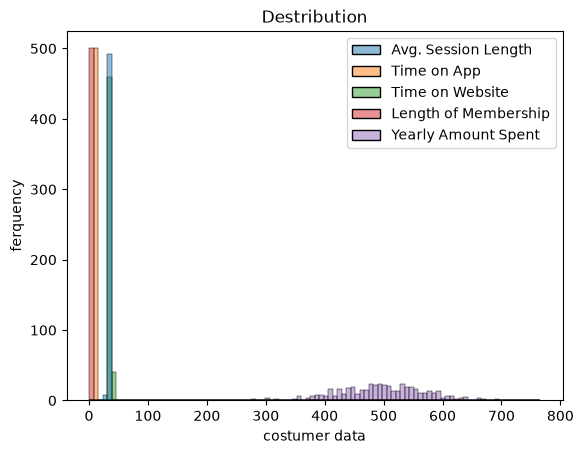

In [6]:
sns.histplot(data=df)
plt.title("Destribution")
plt.xlabel("costumer data")
plt.ylabel("ferquency")
plt.show()


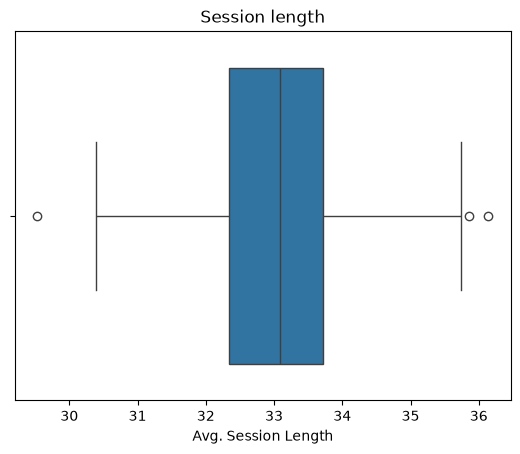

In [7]:
sns.boxplot(data=df, x= "Avg. Session Length")
plt.title("Session length")
plt.show()

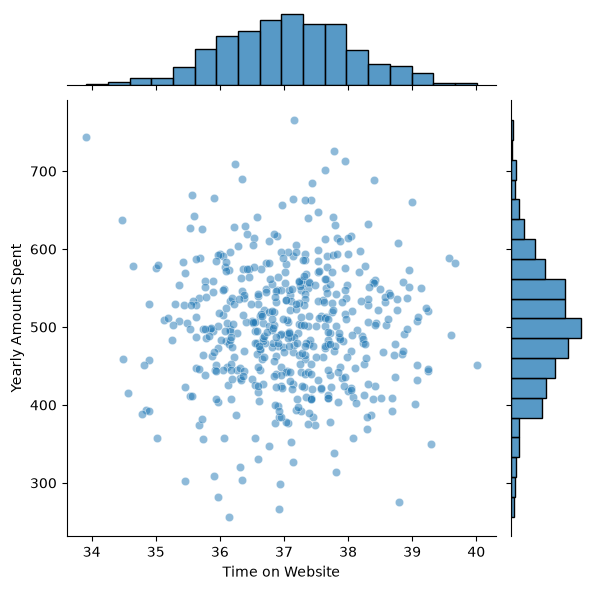

In [8]:
sns.jointplot(alpha =0.5 ,x="Time on Website", y= "Yearly Amount Spent", data=df)

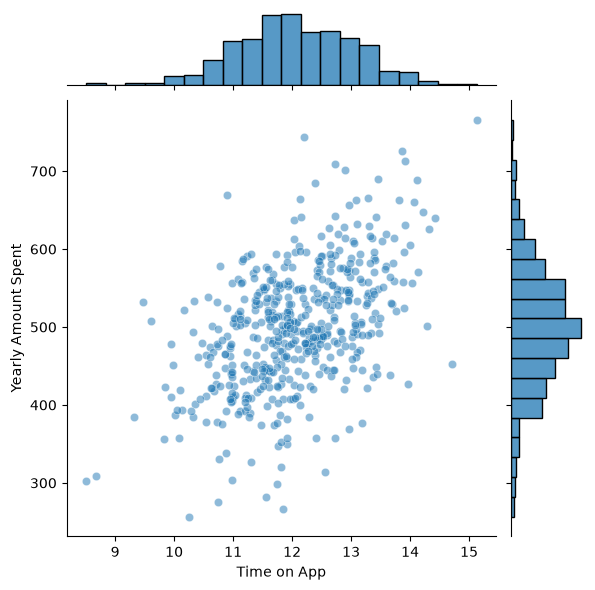

In [9]:
sns.jointplot(alpha =0.5 ,x="Time on App", y= "Yearly Amount Spent", data=df)


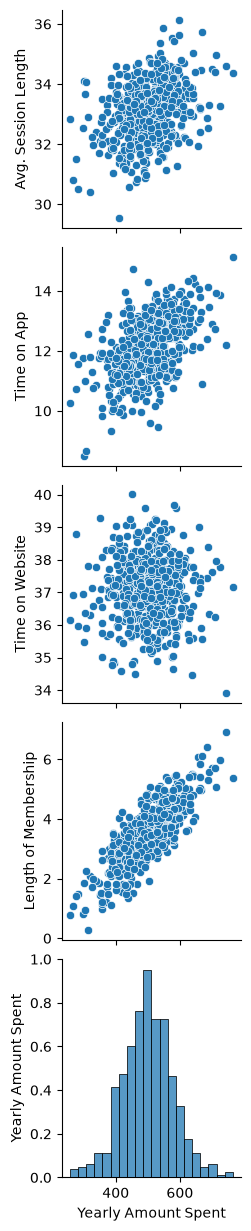

In [10]:
sns.pairplot(data=df, kind= 'scatter',x_vars="Yearly Amount Spent")

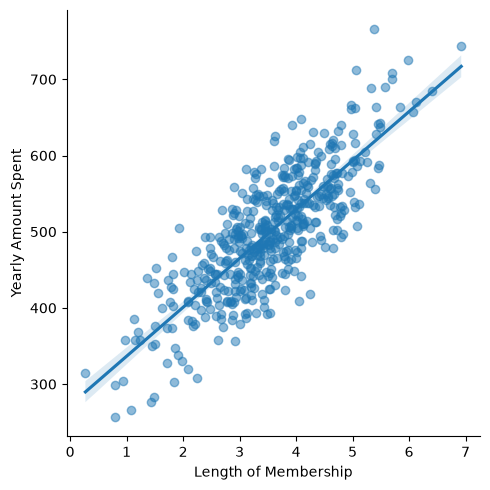

In [11]:
sns.lmplot(data=df, x="Length of Membership",y="Yearly Amount Spent",scatter_kws={'alpha': 0.5})

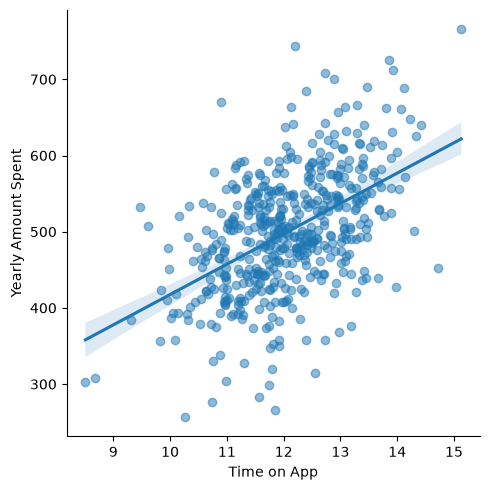

In [12]:
sns.lmplot(data=df, x="Time on App",y="Yearly Amount Spent",scatter_kws={'alpha': 0.5})


In [13]:
from sklearn.model_selection import train_test_split

In [14]:
x= df.drop(columns= ["Yearly Amount Spent","Email","Address","Avatar"])
y = df['Yearly Amount Spent']

In [15]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=12)

In [16]:
x_train

,Avg. Session Length,Time on App,Time on Website,Length of Membership
482,30.971676,11.731364,36.074551,4.426364
137,34.558295,11.281445,36.494406,2.491672
306,31.912076,11.792972,36.257819,2.395168
400,33.172331,13.078692,37.329819,5.405406
43,32.893981,11.529878,36.888086,4.643259
...,...,...,...,...
241,32.686245,12.638572,36.097221,4.297737
253,31.724203,13.172287,36.199753,3.557814
390,35.860237,11.730661,36.882149,3.416210
155,32.449522,13.457725,37.238806,2.941411


In [17]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [18]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[25.45,39.07, 0.29,61.76]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Avg. Session Length','Time on App','Time on Website', 'Length of Membership']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1042
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [19]:
model.coef_

array([25.45289338, 39.06622076,  0.28818698, 61.76361157])

In [20]:
cdf = pd.DataFrame(model.coef_.T, x.columns, columns=["coef"])
cdf

,coef
Avg. Session Length,25.452893
Time on App,39.066221
Time on Website,0.288187
Length of Membership,61.763612


In [21]:
prediction = model.predict(x_test)
prediction

array([532.02062767, 423.86668587, 572.73223753, 532.20818263,
       548.91779071, 577.95357592, 526.11053679, 418.16419112,
       517.23803469, 527.40187054, 460.88427062, 480.78738348,
       543.24088137, 374.89014927, 473.85966919, 542.54076473,
       535.18058509, 616.29317944, 414.13360784, 685.9430595 ,
       447.8275871 , 402.3231767 , 456.91269916, 352.76157689,
       535.70109795, 525.61750023, 547.22446738, 442.08503505,
       580.53248128, 509.46005915, 507.88539699, 540.80887907,
       513.15105142, 523.3378827 , 525.39438706, 380.12157855,
       536.23529064, 479.09266422, 548.62579528, 424.88152676,
       399.02015256, 489.84866925, 612.0197942 , 445.27965242,
       355.21316805, 511.14100116, 494.58137396, 557.78839131,
       585.67712556, 500.18409126, 519.91486789, 447.08620174,
       452.29698183, 466.27497647, 542.51830781, 478.4995887 ,
       400.4284267 , 516.72078289, 562.87923459, 485.13749043,
       478.90626443, 506.47458996, 602.0400693 , 685.36

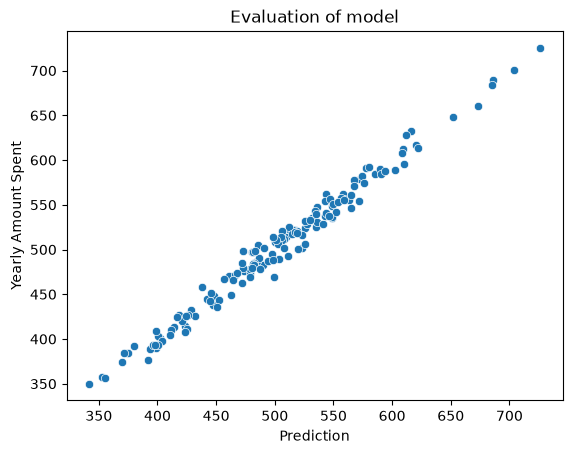

In [22]:
sns.scatterplot(x=prediction, y=y_test)
plt.xlabel("Prediction")
plt.title("Evaluation of model")
plt.show()

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error

In [24]:
print("mean_absolute_error is: ", mean_absolute_error(y_test, prediction))
print("mean_squared_error is: ", mean_squared_error(y_test, prediction))
print("root_mean_squared_error is: ", root_mean_squared_error(y_test, prediction))

mean_absolute_error is:  7.602998610621074
mean_squared_error is:  91.33986453504927
root_mean_squared_error is:  9.557189154508206


In [25]:
import joblib

joblib.dump(model, 'e-commerce.joblib')

print("تم حفظ النموذج بنجاح!")

تم حفظ النموذج بنجاح!
